In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
import pickle

In [2]:
import bacteria_id_config
bacteria_names = list(bacteria_id_config.STRAINS.values())

In [3]:
T = np.load("/home/intellimath/repos/bacteria-ID/data/wavenumbers.npy")
X = np.load("/home/intellimath/repos/bacteria-ID/data/X_finetune.npy")
y = np.load("/home/intellimath/repos/bacteria-ID/data/y_finetune.npy")
X_test = np.load("/home/intellimath/repos/bacteria-ID/data/X_test.npy")
y_test = np.load("/home/intellimath/repos/bacteria-ID/data/y_test.npy")
X_2018 = np.load("/home/intellimath/repos/bacteria-ID/data/X_2018clinical.npy")
X_2019 = np.load("/home/intellimath/repos/bacteria-ID/data/X_2019clinical.npy")
y_2018 = np.load("/home/intellimath/repos/bacteria-ID/data/y_2018clinical.npy")
y_2019 = np.load("/home/intellimath/repos/bacteria-ID/data/y_2019clinical.npy")
print(X.shape, y.shape, T.shape)
print(X_2018.shape, y_2018.shape)
print(X_2019.shape, y_2019.shape)

# print("origin\t", np.unique(y))
# print("test\t", np.unique(y_test))
# print("2018\t", np.unique(y_2018))
# print("2019\t", np.unique(y_2019))

(3000, 1000) (3000,) (1000,)
(10000, 1000) (10000,)
(2500, 1000) (2500,)


In [4]:
import mlgrad.models as models
import mlgrad.regr as regr
import mlgrad.cls as cls
import mlgrad.pca as pca
import mlgrad.plots as plots
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss
import mlgrad.gd as gd
import mlgrad.smooth as smooth
import mlgrad.inventory as inventory
from mlgrad.af import averaging_function
import mlgrad.avragg as avragg

import rampy
import pybaselines
import random

from irsa import io
from irsa.preprocess import despike, utils
import irsa.widgets as widgets
import irsa.spectra as spectra
import irsa.io as io

import scipy.special as special

from sklearn.preprocessing import scale
# import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score, confusion_matrix

import copy

import ipywidgets
from IPython.display import display, HTML

import sys
print(sys.version)

import bacteria_id_config

# %matplotlib widget

3.13.12 (main, Feb  4 2026, 15:06:39) [GCC 15.2.0]


In [5]:
y_ab = np.empty_like(y)
for i in range(len(y)):
    y_ab[i] = bacteria_id_config.ATCC_GROUPINGS[y[i]]
y_ab_test = np.empty_like(y_test)
for i in range(len(y)):
    y_ab_test[i] = bacteria_id_config.ATCC_GROUPINGS[y_test[i]]

In [6]:
spcol_0 = spectra.objects.SpectraCollection()
for i in range(8):
    key = bacteria_id_config.antibiotics[i]
    spcol_0.spectra[key] = spectra.objects.Spectra(
        T, np.ascontiguousarray(X[y_ab == i]), {"key": key}
    )

spcol_test_0 = spectra.objects.SpectraCollection()
for i in range(8):
    key = bacteria_id_config.antibiotics[i]
    spcol_test_0.spectra[key] = spectra.objects.Spectra(
        T, np.ascontiguousarray(X_test[y_ab_test == i]), {"key": key}
    )


In [7]:
spcol_0.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('Meropenem', '…

In [8]:
def dict_find(d, val):
    for key, v in d.items():
        if v == val:
            return key

In [49]:
def plot_params(params, p_threshold=1.0e-4):
    ax = plt.twinx(plt.gca())
    # ax.plot((0,0), (mod.n_param,0), ls='--', lw=0.5, color='b')
    n_input = params.shape[1]-1
    mask = np.zeros(n_input, np.uint8)
    # n = lfm.n_input
    for param in params:
        param1 = np.asarray(param[1:])
        # print(param1[0])
        param_p = param1.copy()
        param_m = param1.copy()
        param_p[param1 < 0] = 0
        param_m[param1 > 0] = 0
        mask = mask | (abs(param1) > p_threshold)
        ax.vlines(range(n_input), param_m, param_p, color='k')
    ax.minorticks_on()
    s = mask.astype("i").sum()
    plt.title(f'#(abs(param) > {p_threshold}) = {s}')

In [13]:
# i_slider = ipywidgets.IntSlider(value=0, min=0, max=29, step=1)
# i_slider.layout.width="50%"

# j_slider = ipywidgets.IntSlider(value=1, min=0, max=29, step=1, )
# j_slider.layout.width="50%"

# def i_on_value_change(change):
#     i = i_slider.value
#     j_slider.value = i+1

# def j_on_value_change(change):
#     j = j_slider.value
    # i = i_slider.value
#     if j <= i:
#         j_slider.value = i+1
#         return

# i_slider.on_trait_change(i_on_value_change, name="value")

# @ipywidgets.interact(i=i_slider, j=j_slider, continuous_update=False)
# def plot_spectra(i, j):
#     plt.figure(figsize=(12,5))
#     for xx in X[y==i]:
#         plt.plot(T, xx, color='lightblue', linewidth=1.0, alpha=0.25)
#     for xx in X[y==j]:
#         plt.plot(T, xx, color='lightgreen', linewidth=1.0, alpha=0.25)
#     plt.plot(T, X[y==i].mean(axis=0), color='darkblue', linewidth=1.0, label=bacteria_names[i])
#     plt.plot(T, X[y==j].mean(axis=0), color='darkgreen', linewidth=1.0, label=bacteria_names[j])

#     plt.hlines(0, T.min(), T.max(), ls='--', lw=0.5)
#     plt.tight_layout()
#     plt.minorticks_on()
#     plt.legend()
#     plt.show()

In [11]:
XX = np.load("/home/intellimath/repos/bacteria-ID/data/XX_finetune.npy")
XX_test = np.load("/home/intellimath/repos/bacteria-ID/data/XX_test.npy")
# XX_2018 = np.load("/home/intellimath/repos/bacteria-ID/data/XX_2018.npy")
# XX_2019 = np.load("/home/intellimath/repos/bacteria-ID/data/XX_2019.npy")

In [12]:
y_ab = np.empty_like(y)
for i in range(len(y)):
    y_ab[i] = bacteria_id_config.ATCC_GROUPINGS[y[i]]
y_ab_test = np.empty_like(y_test)
for i in range(len(y)):
    y_ab_test[i] = bacteria_id_config.ATCC_GROUPINGS[y_test[i]]

In [15]:
# print(XX_2019.shape, T.shape)

In [13]:
spcol = spectra.objects.SpectraCollection()
for i in range(8):
    key = bacteria_id_config.antibiotics[i]
    spcol.spectra[key] = spectra.objects.Spectra(
        T, np.ascontiguousarray(XX[y_ab == i]), {"key": key}
    )

spcol_test = spectra.objects.SpectraCollection()
for i in range(8):
    key = bacteria_id_config.antibiotics[i]
    spcol_test.spectra[key] = spectra.objects.Spectra(
        T, np.ascontiguousarray(XX_test[y_ab_test == i]), {"key": key}
    )

# spcol_2019 = spectra.objects.SpectraCollection()
# for i in range(30):
#     key = bacteria_id_config.STRAINS[i]
#     spcol_2019.spectra[key] = spectra.objects.Spectra(
#         T, np.ascontiguousarray(XX_2019[y_2019 == i]), {"key": key}
#     )

In [84]:
spcol.plot_spectra(smoothing=False)

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('Meropenem', '…

In [ ]:
spcol_test.plot_spectra()

In [17]:
i_slider = ipywidgets.IntSlider(value=0, min=0, max=8, step=1)
i_slider.layout.width="50%"

j_slider = ipywidgets.IntSlider(value=1, min=0, max=8, step=1, )
j_slider.layout.width="50%"

def i_on_value_change(change):
    i = i_slider.value
    j_slider.value = i+1

def j_on_value_change(change):
    j = j_slider.value
    i = i_slider.value
    if j <= i:
        j_slider.value = i+1
        return

i_slider.on_trait_change(i_on_value_change, name="value")

@ipywidgets.interact(i=i_slider, j=j_slider, continuous_update=False)
def plot_spectra(i, j):
    plt.figure(figsize=(12,5))
    for xx in XX[y==i]:
        plt.plot(T, xx, color='lightblue', linewidth=1.0, alpha=0.25)
    for xx in XX[y==j]:
        plt.plot(T, xx, color='lightgreen', linewidth=1.0, alpha=0.25)
    plt.plot(T, XX[y==i].mean(axis=0), color='darkblue', linewidth=1.0, label=bacteria_id_config.antibiotics[i])
    plt.plot(T, XX[y==j].mean(axis=0), color='darkgreen', linewidth=1.0, label=bacteria_id_config.antibiotics[j])

    plt.hlines(0, T.min(), T.max(), ls='--', lw=0.5)
    plt.tight_layout()
    plt.minorticks_on()
    plt.legend()
    plt.show()

interactive(children=(IntSlider(value=0, description='i', layout=Layout(width='50%'), max=8), IntSlider(value=…

In [14]:
def make_dataset2(spcol, key1, key2):
    sp1, sp2 = spcol[key1], spcol[key2]
    N1, N2 = len(sp1.y), len(sp2.y)
    # print(sp1.y.shape, sp2.y.shape)
    Y = np.concatenate((sp1.y, sp2.y), axis=0)
    Z = np.concatenate((np.ones(N1), -np.ones(N2)))
    return Y, Z

def make_Y(spcol, keys):
    Ys = []
    for key in keys:
        sp = spcol[key]
        Ys.append(sp.y)
    Y = np.concatenate(tuple(Ys), axis=0)
    return Y

def make_dataset22(spcol, keys1, keys2):
    Y1 = make_Y(spcol, keys1)
    Y2 = make_Y(spcol, keys2)
    N1, N2 = len(Y1), len(Y2)
    Y = np.concatenate((Y1, Y2), axis=0)
    Z = np.concatenate((np.ones(N1), -np.ones(N2)))
    return Y, Z

In [15]:
def make_dataset1(spcol, key):
    sp1 = spcol[key]
    y1 = sp1.y
    ys = tuple(sp.y for sp in spcol.spectra.values() if sp.key != key)
    y2 = np.concatenate(ys, axis=0)
    N1, N2 = len(y1), len(y2)
    # print(y1.shape, y2.shape)
    Y = np.concatenate((y1, y2), axis=0)
    Z = np.concatenate((np.ones(N1), -np.ones(N2)))
    return Y, Z

In [16]:
def plot_confusion_matrix(key, mod, Y, Y_test, Z, Z_test):
    label=["others", key]
    cm = confusion_matrix(Z, np.sign(mod.evaluate(Y)))
    cm_test = confusion_matrix(Z_test, np.sign(mod.evaluate(Y_test)))
    plt.figure(figsize=(8,3))
    plt.subplot(1,2,1)
    ax = sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='0.2f',
                     xticklabels=label, yticklabels=label)
    ax.xaxis.tick_top()
    plt.xticks(rotation=90) 
    plt.subplot(1,2,2)
    ax = sns.heatmap(cm_test, annot=True, cmap='YlGnBu', fmt='0.2f',
                     xticklabels=label, yticklabels=label, )
    ax.xaxis.tick_top()
    plt.xticks(rotation=90) 
    plt.show()

def plot_confusion_matrix2(keys, mod, Y, Y_test, Z, Z_test, normalize="true"):
    label=keys
    cm = confusion_matrix(Z, mod(Y), normalize=normalize)
    cm_test = confusion_matrix(Z_test, mod(Y_test), normalize=normalize)
    plt.figure(figsize=(40,20))
    plt.subplot(1,2,1)
    ax = sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='0.2f',
                     xticklabels=label, yticklabels=label)
    ax.xaxis.tick_top()
    plt.xticks(rotation=90) 
    plt.subplot(1,2,2)
    ax = sns.heatmap(cm_test, annot=True, cmap='YlGnBu', fmt='0.2f',
                     xticklabels=label, yticklabels=label, )
    ax.xaxis.tick_top()
    plt.xticks(rotation=90) 
    plt.show()

In [34]:
def plot_pca(Y, Y_test, Z, Z_test):
    c, As, Ls = pca.find_loc_and_pc(Y, 2)
    U = (Y - c) @ As.T
    c_test, As_test, Ls_test = pca.find_loc_and_pc(Y_test, 2)
    U_test = (Y_test - c_test) @ As_test.T
    plt.figure(figsize=(8,4))
    plt.subplot(1,2,1)
    plt.title("Train")
    plt.scatter(U[:,0], U[:,1], s=25, c=Z, edgecolors='k', linewidth=0.5)
    plt.subplot(1,2,2)
    plt.title("Test")
    plt.scatter(U_test[:,0], U_test[:,1], s=25, c=Z_test, edgecolors='k', linewidth=0.5)
    plt.tight_layout()
    plt.show()

def plot_spectra_mean(X, X_test, y, y_test, key1, key2):
    ik1, ik2 = dict_find(bacteria_id_config.antibiotics, key1), dict_find(bacteria_id_config.antibiotics, key2)
    plt.figure(figsize=(12,4))
    plt.plot(X[y == ik1].mean(axis=0), label=key1, color="darkred")
    plt.plot(X_test[y_test == ik1].mean(axis=0), label=key1+"/test", color="brown")
    plt.plot(X[y == ik2].mean(axis=0), label=key2, color="darkblue")
    plt.plot(X_test[y_test == ik2].mean(axis=0), label=key2+"/test", color="blue")
    plt.legend()
    plt.tight_layout()
    plt.minorticks_on()
    plt.grid(ls=":", lw=0.5)
    plt.show()

def plot_spectra_params(mod, Y, Z, p_threshold=1.0e-4):
    plt.figure(figsize=(12,3))
    plt.plot(Y[Z==1].mean(axis=0), label="$+1$")
    plt.plot(Y[Z==-1].mean(axis=0), label="$-1$")
    plt.minorticks_on()
    plt.legend()
    plot_params(mod.body.layers[0].matrix, p_threshold=p_threshold)
    plt.show()

def plot_cm2(lfm, Y, Y_test, Z, Z_test, key1, key2):
    cm = confusion_matrix(Z, np.sign(lfm.evaluate(Y)), normalize="true")
    cm_test = confusion_matrix(Z_test, np.sign(lfm.evaluate(Y_test)), normalize="true")
    labels=[key1, key2]
    plt.figure(figsize=(8,3))
    plt.subplot(1,2,1)
    ax = sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='0.2f',
                     xticklabels=labels, yticklabels=labels, cbar=False)
    ax.xaxis.tick_top()
    plt.xticks(rotation=90) 
    plt.subplot(1,2,2)
    ax = sns.heatmap(cm_test, annot=True, cmap='YlGnBu', fmt='0.2f',
                     xticklabels=labels, yticklabels=labels, cbar=False)
    ax.xaxis.tick_top()
    plt.xticks(rotation=90) 
    plt.show()

### One to One

In [57]:
def fit_snn(ys, zs, tau=0, *, n_hidden=7, accuracy_min=0.75, n_try=1, sigma=15.0, p_threshold=1.0e-4):
    Np = (zs>0).sum()
    Nm = (zs<0).sum()
    N = Np + Nm
    weights = np.zeros(N)
    weights[zs > 0] = Nm / N
    weights[zs < 0] = Np / N
    for _ in range(n_try):
        ll = models.LinearLayer(ys.shape[1], n_hidden)
        if tau > 0:
            ll.use_regularizer(funcs2.AbsoluteNorm(), tau)
        fl = models.ScaleLayer(funcs.Sigmoidal(sigma), n_hidden)
        head = models.LinearModel(n_hidden)
        body = models.FFNetworkModel()
        body.add(ll)
        body.add(fl)
        mod = models.FFNetworkFuncModel(head, body)

        mod.allocate()
        mod.init_param()
    
        alg = regr.regression(ys, zs, mod,
                              loss_func=loss.ErrorLoss(funcs.SoftAbs_Sqrt(0.01)),
                              projector=gd.Masked(mod, p_threshold),
                              weights=weights,
                              h=0.005, n_iter=2000)
        inventory.normalize(head.param)
        
        plt.figure(figsize=(10,3))
        plt.plot(alg.lvals)
        plt.show()

        w = accuracy_score(zs, np.sign(mod.evaluate(ys)))
        if w >= accuracy_min:
            break
    return mod

In [18]:
keys_ab_all = list(bacteria_id_config.antibiotics.values())
wg_select1 = ipywidgets.Dropdown(options=keys_ab_all, value=keys_ab_all[0], description="Key1:")
wg_select1.layout.width="75%"
wg_select2 = ipywidgets.Dropdown(options=keys_ab_all, value=keys_ab_all[1], description="Key2:")
wg_select2.layout.width="75%"
key1 = wg_select1.value
key2 = wg_select2.value

def on_value_change1(change):
    key1 = self.wg_select1.value
    i = keys_all.index(key1)
    wg_select2.value = keys_ab_all[i+1 % 30]

# def on_value_change2(change):
#     key2 = self.wg_select2.value

wg_select1.on_trait_change(on_value_change1, name="value")
# wg_select2.on_trait_change(on_value_change2, name="value")


display(wg_select1)
display(wg_select2)

Dropdown(description='Key1:', layout=Layout(width='75%'), options=('Meropenem', 'Ciprofloxacin', 'TZP', 'Vanco…

Dropdown(description='Key2:', index=1, layout=Layout(width='75%'), options=('Meropenem', 'Ciprofloxacin', 'TZP…

In [20]:
key1, key2 = wg_select1.value, wg_select2.value
ik1, ik2 = dict_find(bacteria_id_config.antibiotics, key1), dict_find(bacteria_id_config.antibiotics, key2)
print(ik1, ik2)

5 4


In [21]:
Y, Z = make_dataset2(spcol, key1, key2)
print(Y.shape, Z.shape)
Y_test, Z_test = make_dataset2(spcol_test, key1, key2)
print(Y_test.shape, Z_test.shape)

(900, 1000) (900,)
(900, 1000) (900,)


In [22]:
Y_0, Z_0 = make_dataset2(spcol_0, key1, key2)
# print(Y.shape, Z.shape)
Y_test_0, Z_test_0 = make_dataset2(spcol_test_0, key1, key2)
# print(Y_test.shape, Z_test.shape)

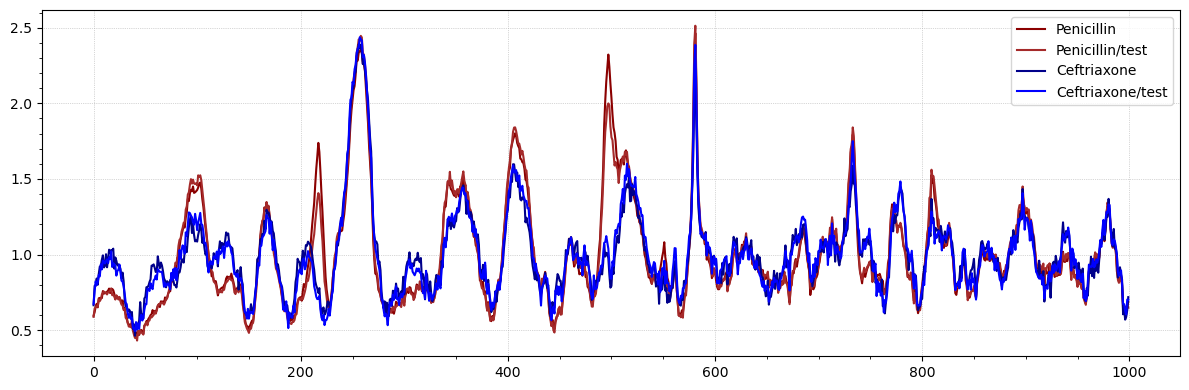

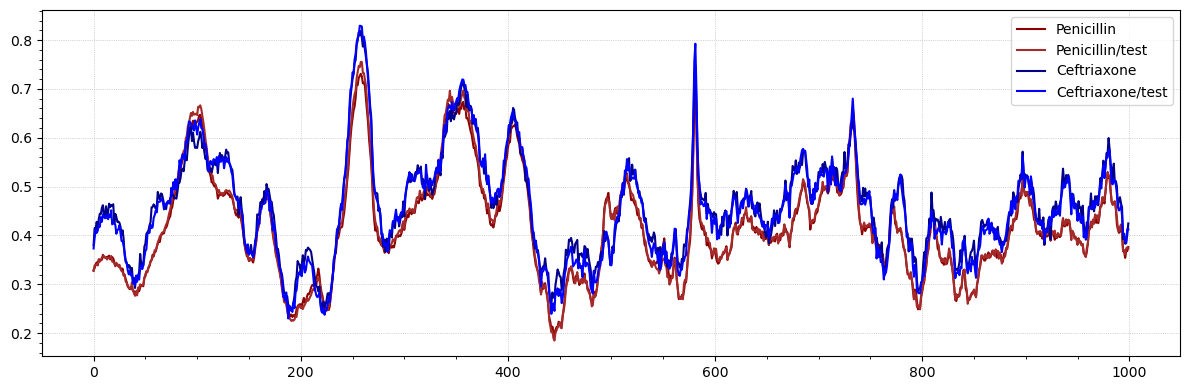

In [23]:
plot_spectra_mean(XX, XX_test, y_ab, y_ab_test, key1, key2)
plot_spectra_mean(X, X_test, y_ab, y_ab_test, key1, key2)

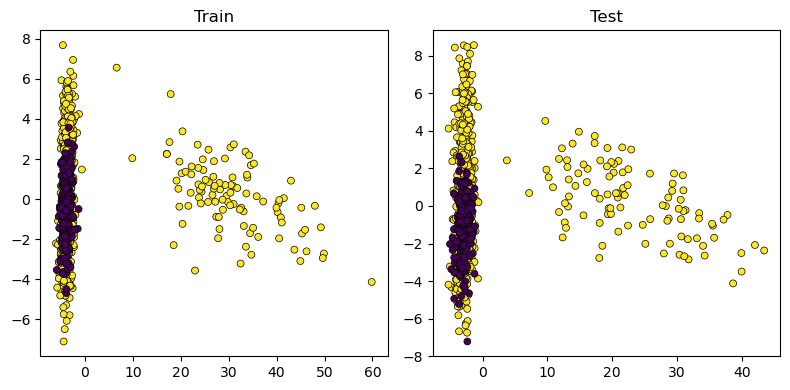

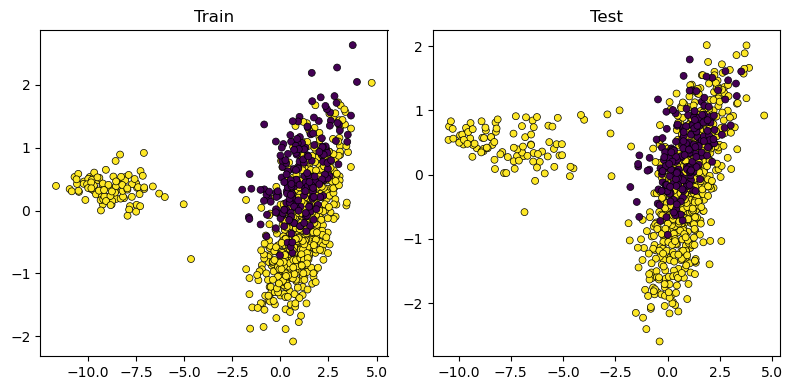

In [24]:
plot_pca(Y, Y_test, Z, Z_test)
plot_pca(Y_0, Y_test_0, Z_0, Z_test_0)

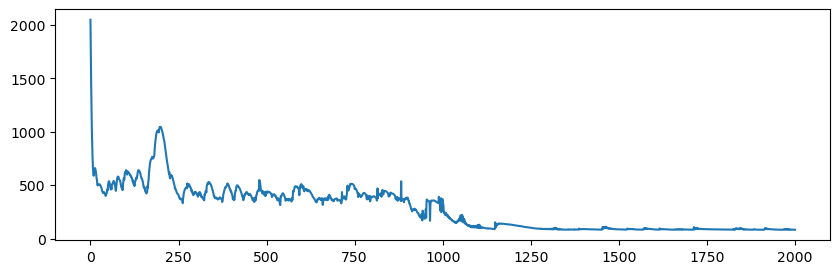

0.9277777777777778
0.8433333333333334



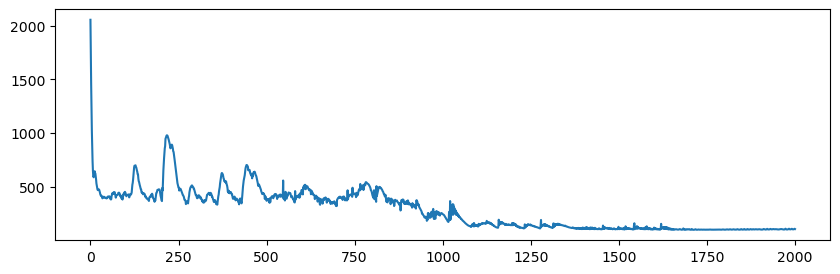

0.95
0.88


In [58]:
snn = fit_snn(Y, Z, tau=10, sigma=15.0, p_threshold=1.0e-5)
print(accuracy_score(Z, np.sign(snn.evaluate(Y))))
print(accuracy_score(Z_test, np.sign(snn.evaluate(Y_test))))
print()
snn_0 = fit_snn(Y_0, Z_0, tau=10, sigma=15.0, p_threshold=1.0e-5)
print(accuracy_score(Z_0, np.sign(snn_0.evaluate(Y_0))))
print(accuracy_score(Z_test_0, np.sign(snn_0.evaluate(Y_test_0))))

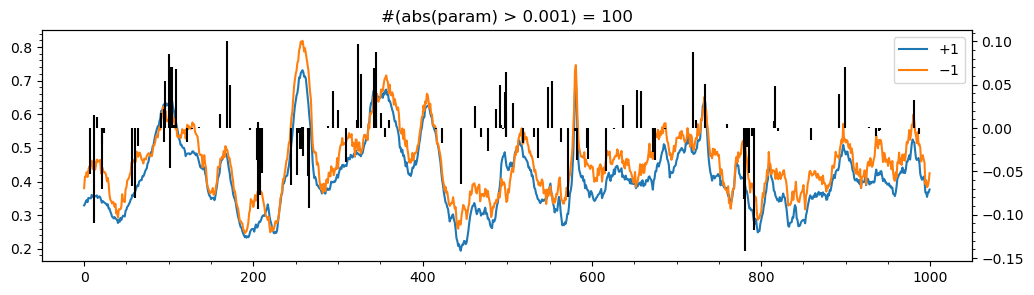

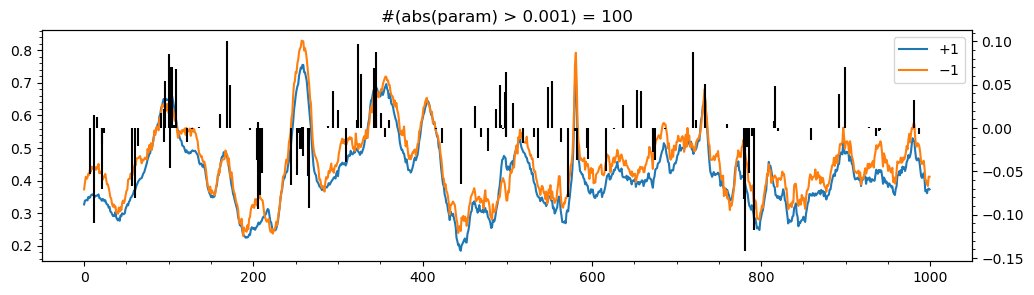

In [59]:
# plot_spectra_params(lfm, Y, Z, 1.0e-5)
# plot_spectra_params(lfm, Y_test, Z_test, 1.0e-3)
plot_spectra_params(snn_0, Y_0, Z_0, 1.0e-3)
plot_spectra_params(snn_0, Y_test_0, Z_test_0, 1.0e-3)

In [ ]:
plot_cm2(lfm, Y, Y_test, Z, Z_test, key1, key2)
plot_cm2(lfm_0, Y_0, Y_test_0, Z_0, Z_test_0, key1, key2)

In [36]:
def generate_mod_ab_all(spcol, spcol_test):
    mod_ab_all = {}
    keys_ab_all = list(bacteria_id_config.antibiotics.values())
    for i in range(8):
        key1 = keys_ab_all[i]
        print(key1)
        for j in range(i+1,8):
            key2 = keys_ab_all[j]
            Y, Z = make_dataset2(spcol, key1, key2)
            Y_test, Z_test = make_dataset2(spcol_test, key1, key2)
            lfm = fit_lfm(Y, Z, tau=20, sigma=15.0)
            mod = models.SimpleComposition(funcs.Sign(), lfm)
            ac = accuracy_score(Z, mod.evaluate(Y))
            ac_test = accuracy_score(Z_test, mod.evaluate(Y_test))
            print(f"\t{key2}\t{ac:.2f} {ac_test:.2f}")
            mod_ab_all[(i,j)] = mod
    return mod_ab_all

In [37]:
mod_ab_all = generate_mod_ab_all(spcol_0, spcol_test_0)

Meropenem
	Ciprofloxacin	0.97 0.97
	TZP	0.98 0.92
	Vancomycin	1.00 0.99
	Ceftriaxone	0.99 0.98
	Penicillin	0.99 0.95
	Daptomycin	1.00 1.00
	Caspofungin	1.00 1.00
Ciprofloxacin
	TZP	1.00 0.90
	Vancomycin	0.98 0.98
	Ceftriaxone	1.00 1.00
	Penicillin	0.99 0.97
	Daptomycin	1.00 1.00
	Caspofungin	1.00 0.99
TZP
	Vancomycin	0.99 0.96
	Ceftriaxone	1.00 0.96
	Penicillin	0.99 0.95
	Daptomycin	1.00 1.00
	Caspofungin	1.00 1.00
Vancomycin
	Ceftriaxone	0.99 0.98
	Penicillin	0.99 0.99
	Daptomycin	0.97 0.99
	Caspofungin	1.00 1.00
Ceftriaxone
	Penicillin	0.98 0.93
	Daptomycin	1.00 1.00
	Caspofungin	1.00 0.99
Penicillin
	Daptomycin	1.00 1.00
	Caspofungin	1.00 1.00
Daptomycin
	Caspofungin	1.00 1.00
Caspofungin


In [39]:
mod_ab_models = []
for i,j in mod_ab_all:
    mod = mod_ab_all[(i,j)]
    mod_ab_models.append(((i,j), mod.as_dict()))

In [50]:
with open("mod_ab_models.pickle", "wb") as f:
    pickle.dump(mod_ab_models, f, protocol=4)

In [ ]:
with open("mod_ab_models.json", "r") as f:
    mod_ab_models = json.load(f)
mod_ab_all = {}
for ij, mod_dict in mod_ab_models:
    mod = models.model_from_dict(mod_dict)
    mod_ab_all[tuple(ij)] = mod

In [40]:
def build_gen_model(mod_ab_all, indices, X):
    n = X.shape[1]
    gen_ab_model = models.GeneralModelLayer(X.shape[1])
    for i in indices:
        lfm_i = models.LinearFuncModel()
        X_i = X[y_ab == i]
        y_i = np.ones(len(X_i))
        for j in indices:
            if j == i:
                continue
            X_j = X[y_ab == j]
            y_j = np.ones(len(X_j))
            if i < j:
                mod = mod_ab_all[(i,j)]
                y_ij = np.concatenate((y_i,-y_j))
                X_ij = np.ascontiguousarray(np.concatenate((X_i,X_j), axis=0))
                w_ij = accuracy_score(np.sign(mod.evaluate(X_ij)), y_ij)
                lfm_i.add(models.SimpleComposition(funcs.Sign(), mod), w_ij)
            elif j < i:
                mod = mod_ab_all[(j,i)]
                y_ji = np.concatenate((y_j,-y_i))
                X_ji = np.ascontiguousarray(np.concatenate((X_j,X_i), axis=0))
                w_ji = accuracy_score(np.sign(mod.evaluate(X_ji)), y_ji)
                lfm_i.add(models.SimpleComposition(funcs.Sign(), mod), -w_ji)
        gen_ab_model.add(lfm_i)
    gen_ab_model.allocate()
    return gen_ab_model

def gen_model_evaluate(gen_model, X, Y):
    N = X.shape[0]
    Y = np.empty((N, gen_model.n_output), "d")
    for k in range(N):
        gen_model.forward(X[k])
        Y[k,:] = gen_model.output
    return np.argmax(Y, axis=1)

def gen_model_plot(gen_model, indices, X, X_test, y, y_test):
    keys_all = list(bacteria_id_config.STRAINS.values())
    keys = [keys_all[i] for i in indices]
    n = len(keys)

    y1 = np.array([yi for yi in y if yi in indices], 'i')
    X1 = np.array([xx for yi, xx in zip(y, X) if yi in indices])
    y_gen1 = gen_model_evaluate(gen_model, X1)
    for i,j in enumerate(indices):
        y_gen1[y_gen1 == i] = j

    y1_test = np.array([yi for yi in y_test if yi in indices], 'i')
    X1_test = np.array([xx for yi, xx in zip(y_test, X_test) if yi in indices])
    y_gen1_test = gen_model_evaluate(gen_model, X1_test)
    for i,j in enumerate(indices):
        y_gen1_test[y_gen1_test == i] = j

    plt.figure(figsize=(3.0*n,2.0*n))
    plt.subplot(1,2,1)
    cm = confusion_matrix(y1, y_gen1)
    plt.title("Training set")
    ax = sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='0.0f',
                     xticklabels=keys, yticklabels=keys, cbar=False)
    ax.xaxis.tick_top()
    plt.xticks(rotation=90) 
    plt.subplot(1,2,2)
    cm_test = confusion_matrix(y1_test, y_gen1_test)
    plt.title("Testing set")
    ax = sns.heatmap(cm_test, annot=True, cmap='YlGnBu', fmt='0.0f',
                     xticklabels=keys, yticklabels=keys, cbar=False)
    ax.xaxis.tick_top()
    plt.xticks(rotation=90) 
    plt.tight_layout()
    plt.show()        

In [41]:
gen_ab_model = build_gen_model(mod_ab_all, [0,1,2,3,4,5,6,7], X)

In [42]:
y_ab_gen = gen_model_evaluate(gen_ab_model, X, y_ab)

In [43]:
y_ab_gen_test = gen_model_evaluate(gen_ab_model, X_test, y_ab_test)

(8, 8)


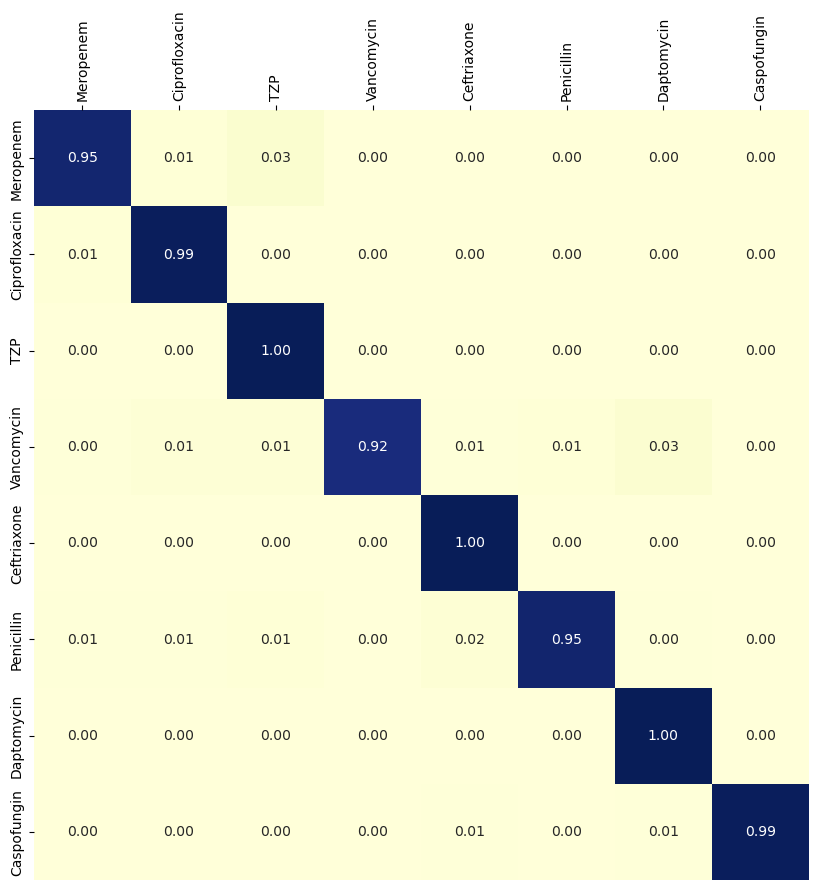

In [44]:
cm = confusion_matrix(y_ab, y_ab_gen, normalize="true")
print(cm.shape)
plt.figure(figsize=(10,10))
ax = sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='0.2f',
                 xticklabels=keys_ab_all, yticklabels=keys_ab_all, cbar=False)
ax.xaxis.tick_top()
plt.xticks(rotation=90)
plt.show()

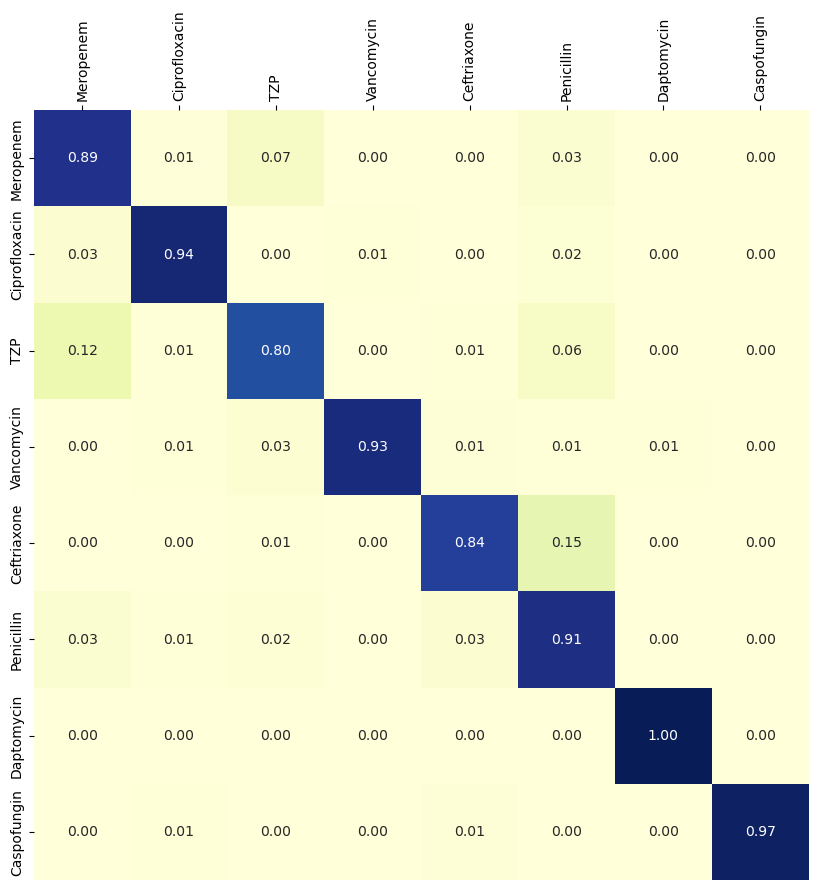

In [45]:
# keys_all = list(bacteria_id_config.STRAINS.values())
cm = confusion_matrix(y_ab_test, y_ab_gen_test, normalize="true")
plt.figure(figsize=(10,10))
ax = sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='0.2f',
                 xticklabels=keys_ab_all, yticklabels=keys_ab_all, cbar=False)
ax.xaxis.tick_top()
plt.xticks(rotation=90) 
plt.show()

In [20]:
# mod_ab_all2 = {}
# keys_ab_all2 = list(bacteria_id_config.antibiotics.values())
# for i in range(8):
#     key1 = keys_ab_all2[i]
#     print(key1)
#     for j in range(i+1,8):
#         key2 = keys_ab_all2[j]
#         Y, Z = make_dataset2(spcol, key1, key2)
#         Y_test, Z_test = make_dataset2(spcol_test, key1, key2)
#         lfm = fit_lfm(Y, Z, tau=10, sigma=10.0)
#         mod = models.SimpleComposition(funcs.Sign(), lfm)
#         ac = accuracy_score(Z, mod.evaluate(Y))
#         ac_test = accuracy_score(Z_test, mod.evaluate(Y_test))
#         print(f"\t{key2}\t{ac:.2f} {ac_test:.2f}")
#         mod_ab_all2[(i,j)] = mod

In [46]:
mod_ab_all2 = generate_mod_ab_all(spcol, spcol_test)

Meropenem
	Ciprofloxacin	0.99 0.97
	TZP	0.98 0.90
	Vancomycin	1.00 0.97
	Ceftriaxone	1.00 0.97
	Penicillin	0.99 0.89
	Daptomycin	1.00 1.00
	Caspofungin	1.00 1.00
Ciprofloxacin
	TZP	1.00 0.95
	Vancomycin	0.99 0.97
	Ceftriaxone	1.00 1.00
	Penicillin	1.00 0.98
	Daptomycin	1.00 0.99
	Caspofungin	1.00 0.99
TZP
	Vancomycin	0.99 0.95
	Ceftriaxone	1.00 0.90
	Penicillin	0.99 0.92
	Daptomycin	1.00 1.00
	Caspofungin	1.00 0.98
Vancomycin
	Ceftriaxone	1.00 0.97
	Penicillin	1.00 0.98
	Daptomycin	1.00 1.00
	Caspofungin	1.00 1.00
Ceftriaxone
	Penicillin	0.99 0.94
	Daptomycin	1.00 1.00
	Caspofungin	1.00 0.98
Penicillin
	Daptomycin	1.00 1.00
	Caspofungin	1.00 0.99
Daptomycin
	Caspofungin	1.00 1.00
Caspofungin


In [28]:
gen_ab_model2 = build_gen_model(mod_ab_all2, [0,1,2,3,4,5,6,7], XX)

In [29]:
y_ab_gen2 = gen_model_evaluate(gen_ab_model2, XX, y_ab)
y_ab_gen_test2 = gen_model_evaluate(gen_ab_model2, XX_test, y_ab_test)

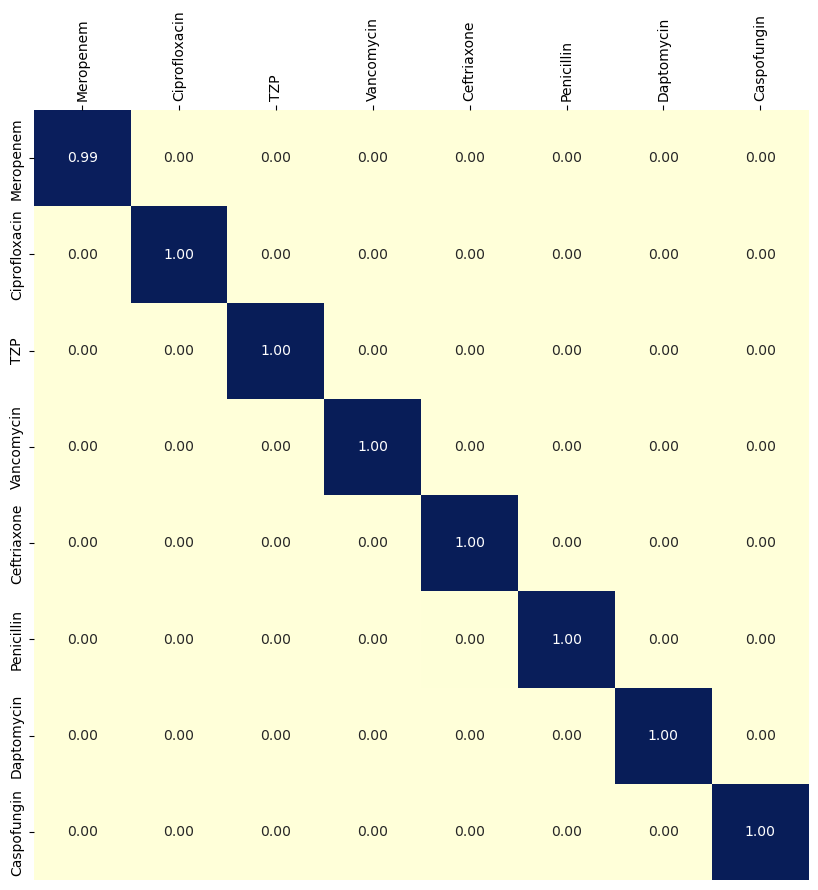

In [33]:
cm = confusion_matrix(y_ab, y_ab_gen2, normalize="true")
plt.figure(figsize=(10,10))
ax = sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='0.2f',
                 xticklabels=keys_ab_all, yticklabels=keys_ab_all, cbar=False)
ax.xaxis.tick_top()
plt.xticks(rotation=90) 
plt.show()

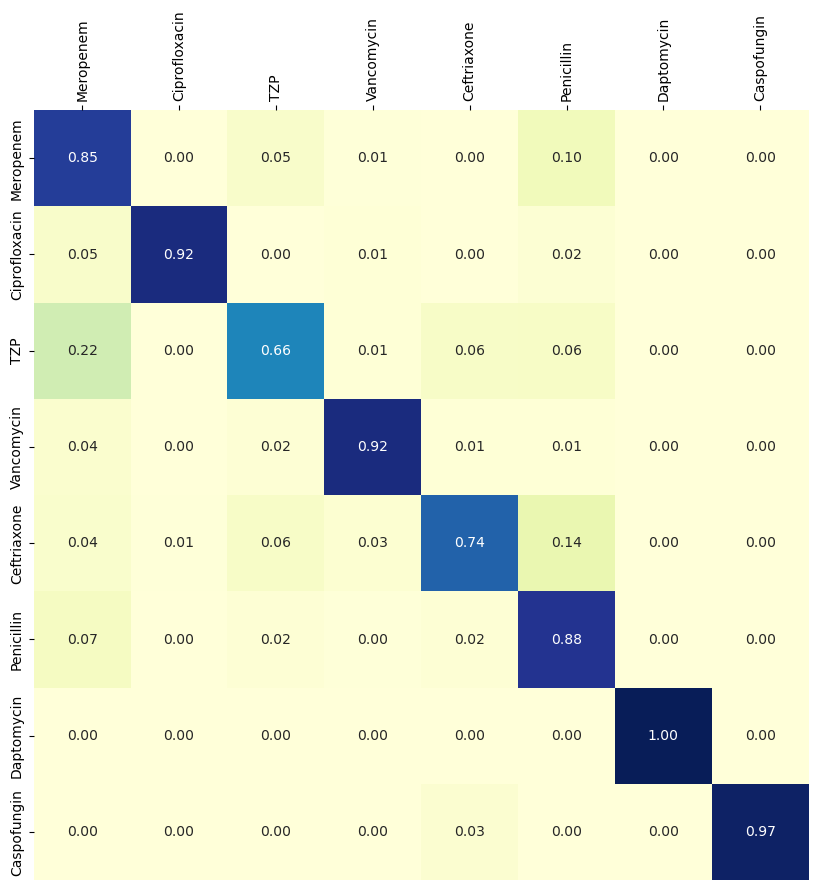

In [35]:
cm = confusion_matrix(y_ab_test, y_ab_gen_test2, normalize="true")
plt.figure(figsize=(10,10))
ax = sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='0.2f',
                 xticklabels=keys_ab_all, yticklabels=keys_ab_all, cbar=False)
ax.xaxis.tick_top()
plt.xticks(rotation=90) 
plt.show()

### One to Others

In [ ]:
display(wg_select1)

In [ ]:
key = wg_select1.value
Y, Z = make_dataset1(spcol, key)
Y_test, Z_test = make_dataset1(spcol_test, key)

In [ ]:
c, As, Ls = pca.find_loc_and_pc(Y, 5)
U = (Y - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(U[:,i], U[:,i+1], s=25, c=Z, edgecolors='k', linewidth=0.5)
    plt.xlabel(str(i+1))
    plt.ylabel(str(i+2))
    # plt.xticks([])
    # plt.yticks([])
    # plt.legend()
plt.tight_layout()
# plt.legend()
plt.show()

plt.figure(figsize=(10,3))
plt.plot(Ls/Ls.sum(), marker='o')
plt.grid(ls=':', lw=0.5)
plt.minorticks_on()
plt.show()

In [ ]:
snn = fit_snn(Y, Z, n_hidden=93, tau=3)
# print(lfm.weights.asarray())
# inventory.normalize(snn.weights.asarray())
print(accuracy_score(Z, np.sign(snn.evaluate(Y))))
print(accuracy_score(Z_test, np.sign(snn.evaluate(Y_test))))
cm = confusion_matrix(Z, np.sign(snn.evaluate(Y)), normalize="true")
cm_test = confusion_matrix(Z_test, np.sign(snn.evaluate(Y_test)), normalize="true")

In [ ]:
plot_confusion_matrix(key, snn, Y, Y_test, Z, Z_test)

In [ ]:
mods = []
for key in bacteria_id_config.STRAINS.values():
    print(key)
    Y, Z = make_dataset1(spcol, key)
    Y_test, Z_test = make_dataset1(spcol_test, key)
    snn = fit_snn(Y, Z, tau=5, n_hidden=30)
    plot_confusion_matrix(key, snn, Y, Y_test, Z, Z_test)    
    mods.append(snn)

In [ ]:
def clsmod(X):
    U = np.c_[tuple(mod.evaluate(X) for mod in mods)]
    return np.argmax(U, axis=1)

In [ ]:
print(accuracy_score(y, clsmod(XX)))
print(accuracy_score(y_test, clsmod(XX_test)))

In [ ]:
plot_confusion_matrix2(bacteria_id_config.STRAINS.values(), clsmod, y, y_test, clsmod(XX), clsmod(XX_test))